# Parte Comum: EDA relacional do Obesity

Dataset: Obesity (UCI 544), arquivo tratado `out/parte_comum/obesity_tratado.csv`.

Pilar coberto neste notebook: **relacional** (relações entre variáveis preditoras e a variável de classe `NObeyesdad`), complementando `eda_comum.ipynb`.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, kruskal

CAMINHO_DADOS = Path("../../out/parte_comum/obesity_tratado.csv")
PASTA_SAIDA = Path("../../out/parte_comum")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CAMINHO_DADOS)
COLUNA_CLASSE = "NObeyesdad"
ORDEM_CLASSES = [
    "Insufficient_Weight", "Normal_Weight",
    "Overweight_Level_I", "Overweight_Level_II",
    "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III",
]
assert set(df[COLUNA_CLASSE].unique()) == set(ORDEM_CLASSES)

colunas_numericas = df.select_dtypes(include="number").columns.tolist()
colunas_categoricas = df.select_dtypes(exclude="number").columns.drop(COLUNA_CLASSE).tolist()
print(f"Shape: {df.shape} | Numericas: {len(colunas_numericas)} | Categoricas: {len(colunas_categoricas)}")

Shape: (2111, 17) | Numericas: 8 | Categoricas: 8


## 1. Correlação entre variáveis numéricas (Pearson e Spearman)

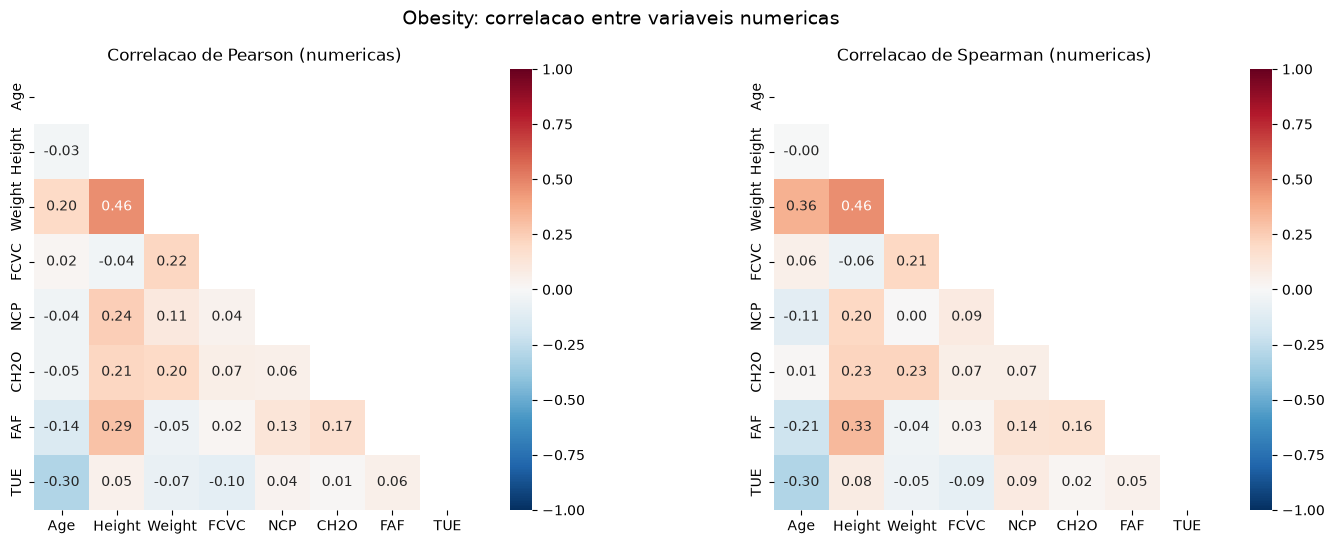

pearson  spearman  abs_pearson
Weight Height    0.463     0.463        0.463
TUE    Age      -0.297    -0.298        0.297
FAF    Height    0.295     0.326        0.295
NCP    Height    0.244     0.204        0.244
FCVC   Weight    0.216     0.208        0.216
CH2O   Height    0.213     0.225        0.213
Weight Age       0.203     0.357        0.203
CH2O   Weight    0.201     0.226        0.201
FAF    CH2O      0.167     0.156        0.167
       Age      -0.145    -0.208        0.145

In [2]:
corr_pearson = df[colunas_numericas].corr(method="pearson")
corr_spearman = df[colunas_numericas].corr(method="spearman")
mascara = np.triu(np.ones_like(corr_pearson, dtype=bool))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(corr_pearson, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title("Correlacao de Pearson (numericas)")

sns.heatmap(corr_spearman, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=axes[1])
axes[1].set_title("Correlacao de Spearman (numericas)")

fig.suptitle("Obesity: correlacao entre variaveis numericas", fontsize=14)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_relacional_correlacao_comum.png", dpi=150, bbox_inches="tight")
plt.show()

pares = (
    corr_pearson.where(~mascara)
    .stack()
    .rename("pearson")
    .to_frame()
    .assign(spearman=corr_spearman.where(~mascara).stack())
    .assign(abs_pearson=lambda x: x["pearson"].abs())
    .sort_values("abs_pearson", ascending=False)
)
pares.head(10).round(3)

## 2. Variáveis numéricas vs. Classe (`NObeyesdad`)

Avaliamos quais variáveis numéricas mais separam as 7 classes com o teste de **Kruskal-Wallis** ($H$) e tamanho de efeito $\epsilon^2 = H / (n - 1)$, além do perfil médio padronizado (z-score) por classe.

In [3]:
resultados_num = []
n_total = len(df)
for coluna in colunas_numericas:
    grupos = [df.loc[df[COLUNA_CLASSE] == c, coluna].dropna().values for c in ORDEM_CLASSES]
    stat, pval = kruskal(*grupos)
    resultados_num.append({
        "variavel": coluna,
        "kruskal_H": round(stat, 2),
        "p_valor": pval,
        "epsilon2": round(stat / (n_total - 1), 4),
    })

df_kruskal = pd.DataFrame(resultados_num).sort_values("epsilon2", ascending=False).set_index("variavel")
display(df_kruskal)

medias_por_classe = df.groupby(COLUNA_CLASSE)[colunas_numericas].mean().reindex(ORDEM_CLASSES).round(2)
medias_por_classe

,kruskal_H,p_valor,epsilon2
variavel,,,
Weight,1822.17,0.000000e+00,0.8636
FCVC,650.06,3.689341e-137,0.3081
Age,541.77,8.378269e-114,0.2568
NCP,230.95,4.798926e-47,0.1095
Height,219.29,1.472625e-44,0.1039
CH2O,94.75,3.120493e-18,0.0449
FAF,88.42,6.447924e-17,0.0419
TUE,45.04,4.601563e-08,0.0213


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
NObeyesdad,,,,,,,,
Insufficient_Weight,19.78,1.69,49.91,2.48,2.91,1.87,1.25,0.84
Normal_Weight,21.74,1.68,62.16,2.33,2.74,1.85,1.25,0.68
Overweight_Level_I,23.42,1.69,74.27,2.26,2.50,2.06,1.06,0.61
Overweight_Level_II,27.00,1.70,82.09,2.26,2.50,2.03,0.96,0.70
Obesity_Type_I,25.88,1.69,92.87,2.19,2.43,2.11,0.99,0.68
Obesity_Type_II,28.23,1.77,115.31,2.39,2.74,1.88,0.97,0.52
Obesity_Type_III,23.50,1.69,120.94,3.00,3.00,2.21,0.66,0.60


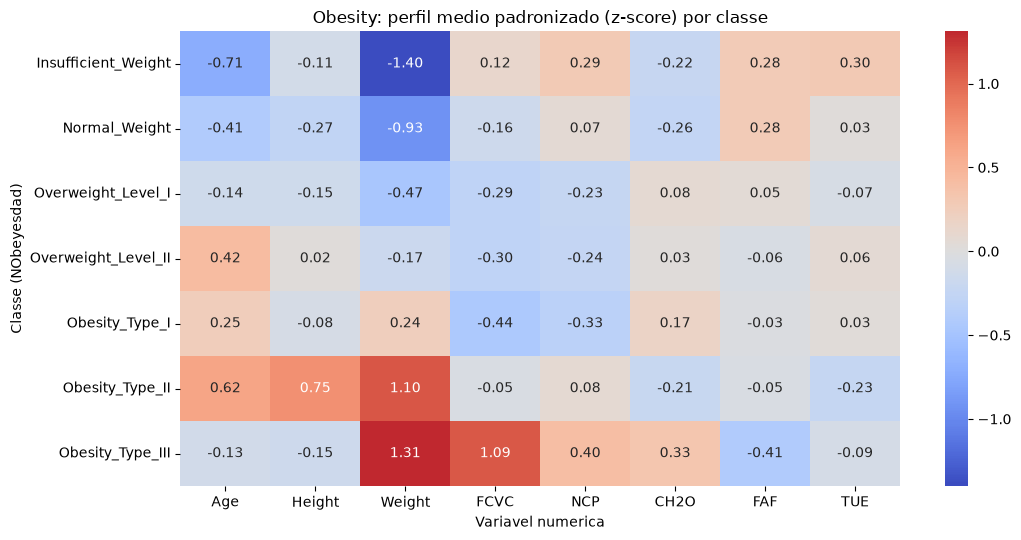

In [4]:
z_df = (df[colunas_numericas] - df[colunas_numericas].mean()) / df[colunas_numericas].std()
z_df[COLUNA_CLASSE] = df[COLUNA_CLASSE]
perfil_z = z_df.groupby(COLUNA_CLASSE)[colunas_numericas].mean().reindex(ORDEM_CLASSES)

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Obesity: perfil medio padronizado (z-score) por classe")
ax.set_xlabel("Variavel numerica")
ax.set_ylabel("Classe (NObeyesdad)")
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_relacional_perfil_classes.png", dpi=150, bbox_inches="tight")
plt.show()

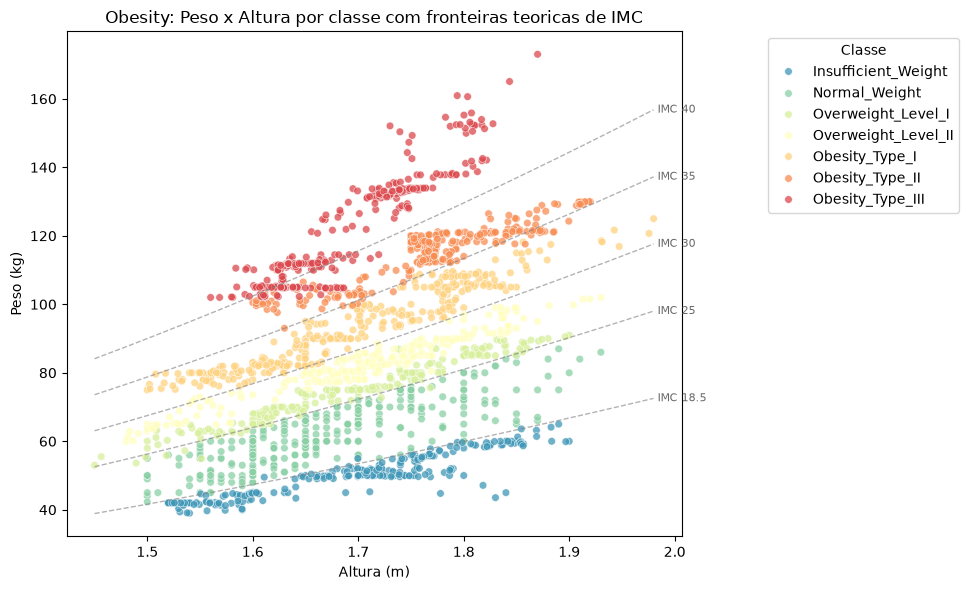

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=df, x="Height", y="Weight", hue=COLUNA_CLASSE,
    hue_order=ORDEM_CLASSES, palette="Spectral_r", alpha=0.75, s=30, ax=ax
)
h_grid = np.linspace(df["Height"].min(), df["Height"].max(), 200)
for imc, rotulo in [(18.5, "IMC 18.5"), (25, "IMC 25"), (30, "IMC 30"), (35, "IMC 35"), (40, "IMC 40")]:
    ax.plot(h_grid, imc * (h_grid ** 2), "--", color="gray", alpha=0.6, linewidth=1)
    ax.text(h_grid[-1], imc * (h_grid[-1] ** 2), f" {rotulo}", fontsize=8, va="center", color="dimgray")

ax.set_title("Obesity: Peso x Altura por classe com fronteiras teoricas de IMC")
ax.set_xlabel("Altura (m)")
ax.set_ylabel("Peso (kg)")
ax.legend(title="Classe", bbox_to_anchor=(1.13, 1), loc="upper left")
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_relacional_peso_altura_classe.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Variáveis categóricas vs. Classe (`NObeyesdad`)

Medimos a associação entre cada variável categórica e a classe usando **Qui-Quadrado ($\chi^2$)** e **V de Cramér** ($V \in [0, 1]$).

In [6]:
def cramers_v(tabela: pd.DataFrame) -> tuple[float, float, float]:
    chi2, pval, _, _ = chi2_contingency(tabela)
    n = tabela.to_numpy().sum()
    r, k = tabela.shape
    denom = n * min(r - 1, k - 1)
    v = float(np.sqrt(chi2 / denom)) if denom > 0 else 0.0
    return chi2, pval, v

resultados_cat = []
for coluna in colunas_categoricas:
    tab = pd.crosstab(df[coluna], df[COLUNA_CLASSE])
    chi2, pval, v = cramers_v(tab)
    resultados_cat.append({
        "variavel": coluna,
        "chi2": round(chi2, 2),
        "p_valor": pval,
        "cramers_v": round(v, 4),
    })

df_cramer = pd.DataFrame(resultados_cat).sort_values("cramers_v", ascending=False).set_index("variavel")
df_cramer

,chi2,p_valor,cramers_v
variavel,,,
Gender,657.75,8.088897e-139,0.5582
family_history_with_overweight,621.98,4.228017e-131,0.5428
CAEC,802.98,7.383853e-159,0.3561
FAVC,233.34,1.482236e-47,0.3325
SCC,123.02,3.773176e-24,0.2414
CALC,338.58,5.287158e-61,0.2312
MTRANS,292.59,5.177915e-48,0.1861
SMOKE,32.14,1.535424e-05,0.1234


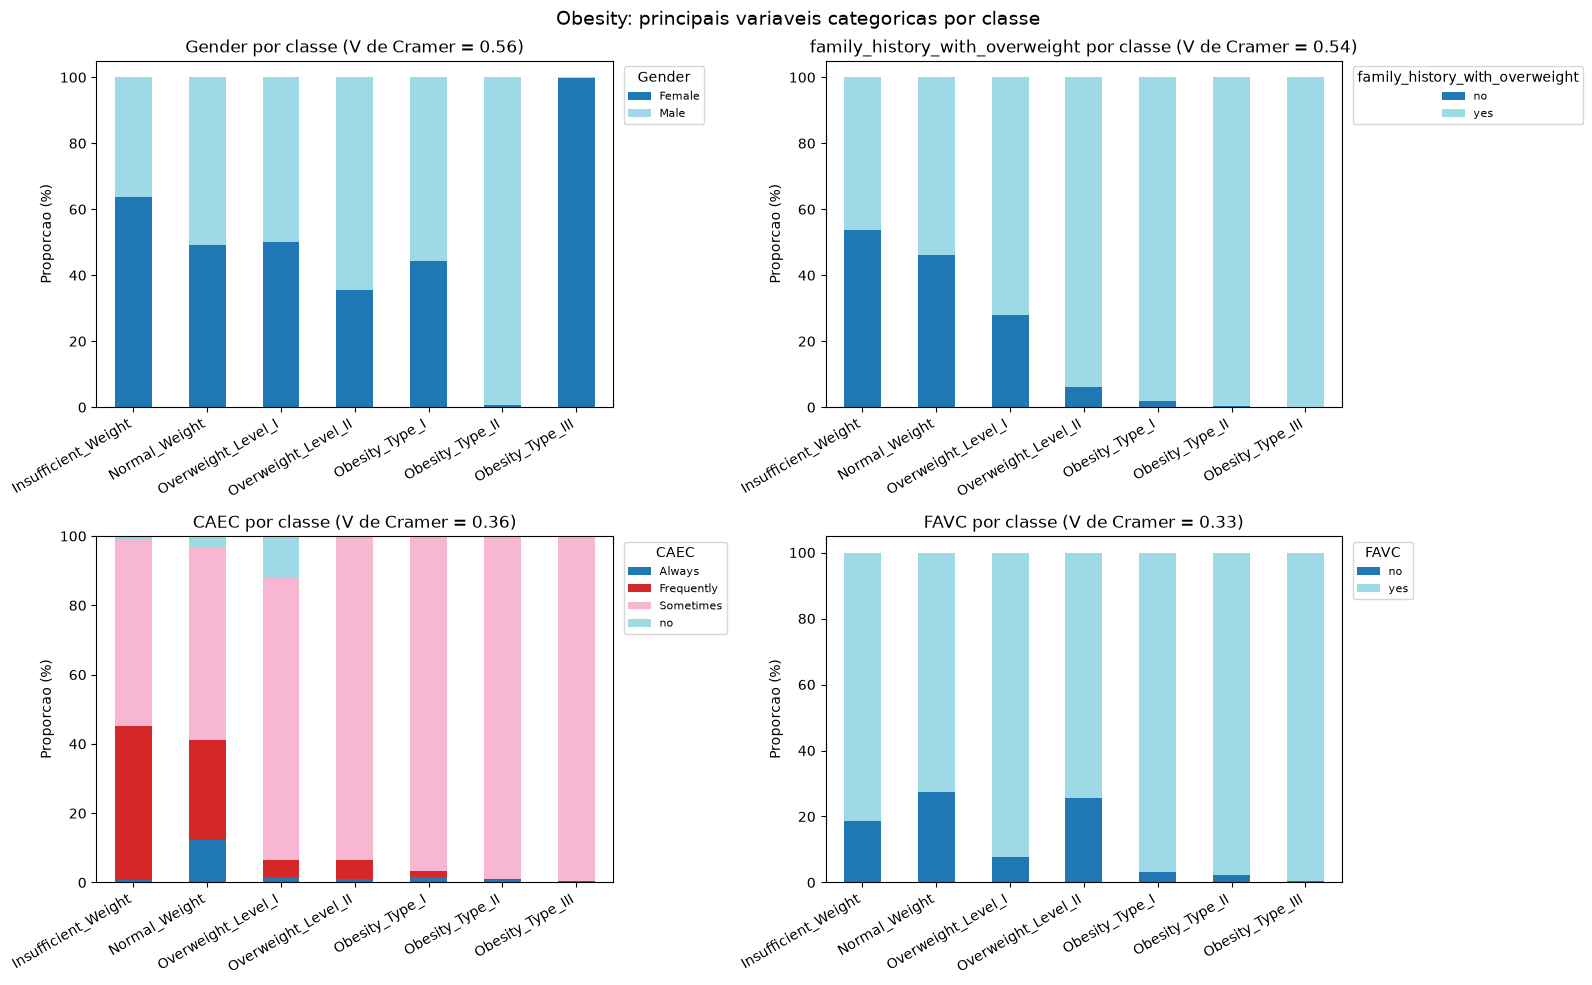

In [7]:
top_cats = df_cramer.index[:4].tolist()
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, coluna in zip(axes.flat, top_cats):
    prop = (pd.crosstab(df[COLUNA_CLASSE], df[coluna], normalize="index") * 100).reindex(ORDEM_CLASSES)
    prop.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")
    v_val = df_cramer.loc[coluna, "cramers_v"]
    ax.set_title(f"{coluna} por classe (V de Cramer = {v_val:.2f})")
    ax.set_ylabel("Proporcao (%)")
    ax.set_xlabel("")
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    ax.legend(title=coluna, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)

fig.suptitle("Obesity: principais variaveis categoricas por classe", fontsize=14)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_relacional_categoricas_classe.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Observações do pilar relacional

- **Relação dominante com a classe:** `Weight` é disparada a variável numérica com maior poder discriminativo entre as 7 classes (maior $H$ e $\epsilon^2$). No gráfico `Peso × Altura`, as classes se alinham quase perfeitamente às faixas teóricas de IMC da OMS.
- **Correlação entre preditoras:** `Weight` e `Height` apresentam correlação positiva moderada (~0,46). As demais variáveis numéricas têm correlações fracas entre si, indicando baixa redundância linear fora do par antropométrico.
- **Sobreposição entre classes intermediárias:** Nas variáveis de hábito (`FCVC`, `NCP`, `CH2O`, `FAF`, `TUE`), o perfil padronizado (z-score) varia pouco entre `Normal_Weight`, `Overweight_Level_I` e `Overweight_Level_II`, o que antecipa confusão entre essas fronteiras no agrupamento K-Means.
- **Associações categóricas:** `family_history_with_overweight`, `CAEC` e `Gender` lideram o V de Cramér. Destaca-se o forte contraste de gênero nos extremos de obesidade (`Obesity_Type_II` concentrada em homens e `Obesity_Type_III` em mulheres), além da presença quase universal de histórico familiar nas classes de obesidade.